 # Q1 Equilibrium conversionchecker 
# in a reactor the reaction a+b=c reaches equilibrium.
# initial concentration [A]=1.5,[B]=1.0 and [C]=0 mol/l.x mol of c is formed,kc=x/((1.5-x)1-x)), which rearrange the quadratic equation 

# Kc*x^2 - (2.5*Kc + 1)*x + 1.5*Kc = 0
 write a code or aprogram as a i am 2nd year chemical engineering student do not write the entire program 


# a. reads Kc using input(),prints the data type of the raw input of the converted value and shows a clear message (no crash) if the text is not a number or if Kc<=0

In [31]:
raw_kc = input("Enter Kc: ")
print("Raw input type:", type(raw_kc))

try:
    Kc = float(raw_kc)
except ValueError:
    print("Error: Kc must be a number.")
else:
    print("Converted value type:", type(Kc))
    if Kc <= 0:
        print("Error: Kc must be greater than 0.")
    else:
        print("Valid Kc:", Kc)

Raw input type: <class 'str'>
Converted value type: <class 'float'>
Valid Kc: 0.5


# b.finds a,b,c, the discriminant and both roots;

In [32]:
import math

a = Kc
b = -(2.5 * Kc + 1)
c = 1.5 * Kc

print("a =", a)
print("b =", b)
print("c =", c)

discriminant = b**2 - 4 * a * c
print("Discriminant =", discriminant)

if discriminant >= 0:
    root1 = (-b + math.sqrt(discriminant)) / (2 * a)
    root2 = (-b - math.sqrt(discriminant)) / (2 * a)
    print("Root 1 =", root1)
    print("Root 2 =", root2)
else:
    print("There are no real roots.")

a = 0.5
b = -2.25
c = 0.75
Discriminant = 3.5625
Root 1 = 4.1374586088176875
Root 2 = 0.36254139118231254


# c. select the physically meaningfull root (0<=x<=1,because B is limiting )

In [12]:
physical_roots = [root for root in (root1, root2) if 0 <= root <= 1]

if physical_roots:
    x_equilibrium = physical_roots[0]
    print("Physically meaningful root (0 <= x <= 1):", x_equilibrium)
else:
    print("No root is in the physical range 0 <= x <= 1.")

Physically meaningful root (0 <= x <= 1): 0.75


# d. prints equilibrium [A],[B],[C] 3 decimals and the conversion of the limiting reactant B=x/[B]*100%

In [13]:
initial_A = 1.5
initial_B = 1.0

A_equilibrium = initial_A - x_equilibrium
B_equilibrium = initial_B - x_equilibrium
C_equilibrium = x_equilibrium
conversion_B = x_equilibrium / initial_B * 100

print(f"Equilibrium [A] = {A_equilibrium:.3f} mol/L")
print(f"Equilibrium [B] = {B_equilibrium:.3f} mol/L")
print(f"Equilibrium [C] = {C_equilibrium:.3f} mol/L")
print(f"Conversion of limiting reactant B = {conversion_B:.3f}%")

Equilibrium [A] = 0.750 mol/L
Equilibrium [B] = 0.250 mol/L
Equilibrium [C] = 0.750 mol/L
Conversion of limiting reactant B = 75.000%


# e. classifies the conversion using if/elif/else>=70% "high", >=40% "moderate", otherwise "low"

In [14]:
if conversion_B >= 70:
    conversion_category = "high"
elif conversion_B >= 40:
    conversion_category = "moderate"
else:
    conversion_category = "low"

print("Conversion category:", conversion_category)

Conversion category: high


# Q2

part A in a batch reactor reactant A is consumed by a first order reaction dc/dt =-kc use the eulers method : C_new = C_old -kC_old dt . take c=2.5 mol/l ,k=0.04 min^-1 dt= 1min 

# 1 using a for loop simulate 12 minutes and print a table of time (min), concentration (mol/l) and conversion %

In [17]:
initial_concentration = 2.5
k = 0.04
dt = 1
concentration = initial_concentration

print(f"{'Time (min)':>10} {'Concentration (mol/L)':>24} {'Conversion (%)':>18}")

for time in range(13):
    if time > 0:
        concentration = concentration - k * concentration * dt

    conversion = (initial_concentration - concentration) / initial_concentration * 100
    print(f"{time:10d} {concentration:24.3f} {conversion:18.2f}")

Time (min)    Concentration (mol/L)     Conversion (%)
         0                    2.500               0.00
         1                    2.400               4.00
         2                    2.304               7.84
         3                    2.212              11.53
         4                    2.123              15.07
         5                    2.038              18.46
         6                    1.957              21.72
         7                    1.879              24.86
         8                    1.803              27.86
         9                    1.731              30.75
        10                    1.662              33.52
        11                    1.596              36.18
        12                    1.532              38.73


# 2 using math.exp(),calculate the exact value ce^(-kt) at 12 min and print the absolute error of the eulers result 

In [18]:
import math

time_final = 12
euler_concentration = concentration
exact_concentration = initial_concentration * math.exp(-k * time_final)
absolute_error = abs(exact_concentration - euler_concentration)

print(f"Exact concentration at {time_final} min = {exact_concentration:.6f} mol/L")
print(f"Euler concentration at {time_final} min = {euler_concentration:.6f} mol/L")
print(f"Absolute error = {absolute_error:.6f} mol/L")

Exact concentration at 12 min = 1.546958 mol/L
Euler concentration at 12 min = 1.531774 mol/L
Absolute error = 0.015184 mol/L


# 3  using  a while loop , repeat the simulation until the conversion reacher 40% or time reaches 100 min . print the time needed and the final conncentration 

In [19]:
initial_concentration = 2.5
k = 0.04
dt = 1
concentration = initial_concentration
time = 0
conversion = 0

while conversion < 40 and time < 100:
    concentration = concentration - k * concentration * dt
    time += dt
    conversion = (initial_concentration - concentration) / initial_concentration * 100

print(f"Time needed = {time} min")
print(f"Final concentration = {concentration:.3f} mol/L")
print(f"Final conversion = {conversion:.2f}%")

if conversion >= 40:
    print("The 40% conversion target was reached.")
else:
    print("The 100-minute limit was reached before 40% conversion.")

Time needed = 13 min
Final concentration = 1.471 mol/L
Final conversion = 41.18%
The 40% conversion target was reached.


 # partB . distillation coloumn sample code such as DIST2026X9Q3 are stored as text . write aprogram that reads a code , loops through each character and prints the number of digits and the sum of digits . show a messagew from a empty code and for a code with no digits 

In [21]:
code = input("Enter the distillation column code: ")

if not code.strip():
    print("Error: the code cannot be empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in code:
        if character.isdigit():
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("No digits were found in the code.")
    else:
        print("Number of digits:", digit_count)
        print("Sum of digits:", digit_sum)

No digits were found in the code.


# q3 

# part A write a recursive function factorial (n) remember the base case of 0! and function combination (n,r)= n!/r!(n-r)! that uses it reject the invalid negative values r>n .

In [22]:
def factorial(n):
    if n < 0:
        raise ValueError("n must be a non-negative integer.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0 or r > n:
        raise ValueError("Require n >= 0 and 0 <= r <= n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


print("9! =", factorial(9))
print("9 choose 3 =", combination(9, 3))

9! = 362880
9 choose 3 = 84


# part b sample are taken as time fibonacci number * 4min . write an iterative function fib_iter(n) that returns a list of the first n .fibbonacci numbers and a recurssive function fib_rec(k) that returns the kth fibbonacci number (F=0 and Fi=1). for n=10 check both functions and print a table : sample no. | fibbonacci tag | sampling time (min)

In [23]:
def fib_iter(n):
    if n < 0:
        raise ValueError("n must be non-negative.")

    numbers = []
    previous, current = 0, 1
    for _ in range(n):
        numbers.append(previous)
        previous, current = current, previous + current
    return numbers


def fib_rec(k):
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k < 2:
        return k
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 10
fibonacci_numbers = fib_iter(n)

print(f"{'Sample no.':>10} {'Fibonacci tag':>18} {'Sampling time (min)':>22}")
for sample_no, fib_number in enumerate(fibonacci_numbers, start=1):
    index = sample_no - 1
    if fib_number != fib_rec(index):
        raise AssertionError("Iterative and recursive results do not match.")

    fibonacci_tag = f"F{index} = {fib_number}"
    sampling_time = fib_number * 4
    print(f"{sample_no:10d} {fibonacci_tag:>18} {sampling_time:22d}")

print("Both functions agree for the first 10 Fibonacci numbers.")

Sample no.      Fibonacci tag    Sampling time (min)
         1             F0 = 0                      0
         2             F1 = 1                      4
         3             F2 = 1                      4
         4             F3 = 2                      8
         5             F4 = 3                     12
         6             F5 = 5                     20
         7             F6 = 8                     32
         8            F7 = 13                     52
         9            F8 = 21                     84
        10            F9 = 34                    136
Both functions agree for the first 10 Fibonacci numbers.


# Q4 

 # cosumption of a reactant was studied in a batch reactor with two feed concentrations of catalyst . the concentration (mol/l)was recorded

time_min          run1_mol_l(low catalyst)         run2_mol_l(high catalyst) 
0                        1.50                           1.50
10                       1.17                           0.96
20                       0.91                           0.61
30                       0.71                           0.39
40                       0.55                           0.25 
50                       0.43                           0.16

# a creates a data frame from this table save it as kinetics.csv without the index coloumn and as kinetics.json. read the CSV back and print its shape and data types

In [24]:
import pandas as pd

kinetics_data = {
    "time_min": [0, 10, 20, 30, 40, 50],
    "run1_mol_l": [1.50, 1.17, 0.91, 0.71, 0.55, 0.43],
    "run2_mol_l": [1.50, 0.96, 0.61, 0.39, 0.25, 0.16],
}

kinetics_df = pd.DataFrame(kinetics_data)
kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=2)

kinetics_from_csv = pd.read_csv("kinetics.csv")
print("Data frame:")
print(kinetics_df)
print("CSV shape:", kinetics_from_csv.shape)
print("CSV data types:")
print(kinetics_from_csv.dtypes)

Data frame:
   time_min  run1_mol_l  run2_mol_l
0         0        1.50        1.50
1        10        1.17        0.96
2        20        0.91        0.61
3        30        0.71        0.39
4        40        0.55        0.25
5        50        0.43        0.16
CSV shape: (6, 3)
CSV data types:
time_min        int64
run1_mol_l    float64
run2_mol_l    float64
dtype: object


# b print the mean and the standard deviation of run1 and run2 and state which run shows more variation 

In [25]:
run1_mean = kinetics_df["run1_mol_l"].mean()
run1_std = kinetics_df["run1_mol_l"].std()
run2_mean = kinetics_df["run2_mol_l"].mean()
run2_std = kinetics_df["run2_mol_l"].std()

print(f"Run 1 mean = {run1_mean:.3f} mol/L")
print(f"Run 1 standard deviation = {run1_std:.3f} mol/L")
print(f"Run 2 mean = {run2_mean:.3f} mol/L")
print(f"Run 2 standard deviation = {run2_std:.3f} mol/L")

if run1_std > run2_std:
    print("Run 1 shows more variation based on standard deviation.")
elif run2_std > run1_std:
    print("Run 2 shows more variation based on standard deviation.")
else:
    print("Both runs have the same standard deviation.")

Run 1 mean = 0.878 mol/L
Run 1 standard deviation = 0.402 mol/L
Run 2 mean = 0.645 mol/L
Run 2 standard deviation = 0.507 mol/L
Run 2 shows more variation based on standard deviation.


# c plot both runs on the graph ( time on x axis )with the title , axix labels with units,legend and grid 

<Axes: title={'center': 'Reactant Concentration vs. Time'}, xlabel='Time (min)', ylabel='Concentration (mol/L)'>

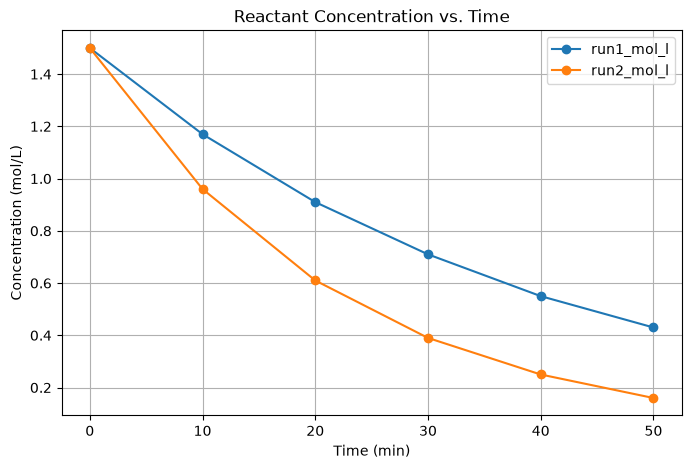

In [28]:
kinetics_df.plot(
    x="time_min",
    y=["run1_mol_l", "run2_mol_l"],
    kind="line",
    marker="o",
    title="Reactant Concentration vs. Time",
    xlabel="Time (min)",
    ylabel="Concentration (mol/L)",
    grid=True,
    figsize=(8, 5),
)

# d ethlyene gas is compressed slowly in a piston- cylinder at a constant  temprature 

volume_L : 1,2,3,4,5
pressure_bar :5.03,2.52,1.65,1.26,1.01

plot a pressure vs volume as a scatter plot . calculate k as the mean of p*v and draw the refrence curve of p=k/v on the same graph . add the titles labels with units and legend 

Mean p*V, k = 5.022 bar L


<Axes: title={'center': 'Ethylene Pressure vs. Volume at Constant Temperature'}, xlabel='volume_L', ylabel='Pressure (bar)'>

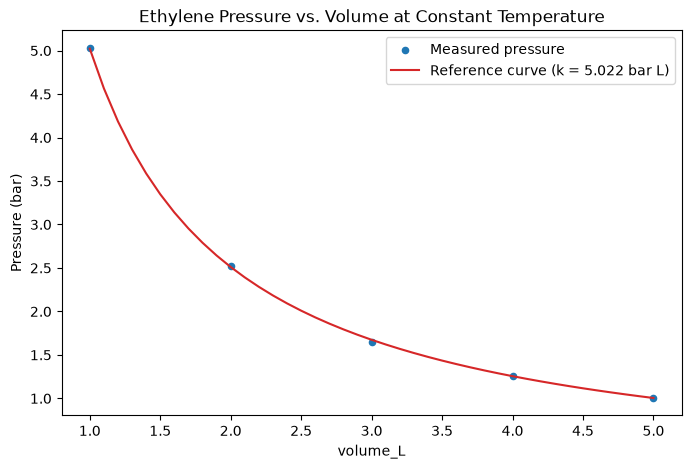

In [30]:
import pandas as pd

pv_data = pd.DataFrame({
    "volume_L": [1, 2, 3, 4, 5],
    "pressure_bar": [5.03, 2.52, 1.65, 1.26, 1.01],
})
pv_data["pv_bar_L"] = pv_data["volume_L"] * pv_data["pressure_bar"]
pv_constant = pv_data["pv_bar_L"].mean()
print(f"Mean p*V, k = {pv_constant:.3f} bar L")

reference_curve = pd.DataFrame({
    "volume_L": [step / 10 for step in range(10, 51)],
})
reference_curve["reference_pressure_bar"] = pv_constant / reference_curve["volume_L"]

ax = pv_data.plot.scatter(
    x="volume_L",
    y="pressure_bar",
    label="Measured pressure",
    title="Ethylene Pressure vs. Volume at Constant Temperature",
    xlabel="Volume (L)",
    ylabel="Pressure (bar)",
    grid=True,
    figsize=(8, 5),
)
reference_curve.plot(
    x="volume_L",
    y="reference_pressure_bar",
    ax=ax,
    color="tab:red",
    label=f"Reference curve (k = {pv_constant:.3f} bar L)",
    legend=True,
)